# Standard DQN vs Double DQN for Pendulum-v0

**Author:** Hoon Chun Fei (solo follow-up to the gravity study)<br>
**Topic:** Reinforcement learning, Double DQN as a targeted extension of DQN

## Research question
> **When the Standard DQN design from the gravity study is held fixed, how does replacing its bootstrap target with Double DQN affect Pendulum control performance, Q-value behaviour, and run-to-run consistency?**

## Working hypothesis
Standard DQN uses a maximisation operation when constructing its bootstrap target. Prior work on Double Q-learning and Double DQN argues that coupling action selection and action evaluation can contribute to overly optimistic value estimates.

Double DQN separates these roles:

- the **Online/Main network selects** the next action;
- the **Target network evaluates** that selected action.

The expectation before training was therefore that DDQN might produce less extreme value-estimation behaviour and potentially better control. Importantly, **value-estimation behaviour and final-policy consistency are treated as separate questions**. DDQN is not assumed in advance to be superior on either.

## Relation to the gravity study
The gravity study (`dqn_pendulum_gravity.ipynb`) established a viable Standard DQN for a discretised Pendulum task. This experiment keeps that successful default-gravity design as the baseline and changes only one algorithmic mechanism: **the TD bootstrap target**.

Shared configuration:

- `Pendulum-v0`, `g=10`
- state: `[cos(theta), sin(theta), angular_velocity]`
- angular velocity normalised by `8`
- five torques: `[-2,-1,0,1,2]`
- two hidden layers: `64 -> 64`, ReLU
- Adam `lr=0.001`
- `gamma=0.99`
- replay buffer `50,000`
- warm-up `1,000` steps
- batch size `64`
- train every `4` environment steps
- epsilon `1.0 -> 0.01`
- hard Target-DQN copy once per episode
- fixed training budget of `500` episodes

All outputs are written to a separate results folder. No evaluation CSV from the gravity study is reused as evidence here.

> **Frozen-output note:** the completed outputs in this notebook are retained as the experimental record. Expensive training/evaluation flags should remain `False` after completion so the six trained agents are not accidentally replaced or selectively rerun.


# 1. Run order

Use the flags below.

1. Run setup and helper cells.
2. Keep `RUN_SMOKE_TESTS=True` once and confirm both algorithms pass.
3. Set `RUN_DQN_TRAINING=True`; run the training cell once; then set it back to `False`.
4. Set `RUN_DDQN_TRAINING=True`; run the training cell once; then set it back to `False`.
5. Set `RUN_FINAL_EVALUATION=True`; run the evaluation cell once; then set it back to `False`.
6. Keep `SHOW_ANALYSIS_PLOTS=True` to rebuild plots from saved CSVs.

After a full run, leave all expensive flags `False`.

In [1]:
# Install only if packages are missing.
# %pip install "numpy<2" "gym==0.17.3" tensorflow pandas matplotlib

import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import gym

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Gym:", gym.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

assert gym.__version__ == "0.17.3", "This notebook targets gym==0.17.3."

Python: 3.9.25
NumPy: 1.23.5
Pandas: 2.3.3
TensorFlow: 2.10.0
Gym: 0.17.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# -------------------------- SAFE RUN FLAGS --------------------------
RUN_SMOKE_TESTS = False
RUN_DQN_TRAINING = False
RUN_DDQN_TRAINING = False
RUN_FINAL_EVALUATION = False
FORCE_RETRAIN = False
SHOW_ANALYSIS_PLOTS = True
# -------------------------------------------------------------------

GRAVITY = 10.0
RUN_NUMBERS = [1, 2, 3]

# Fixed equal budget for a controlled DQN-vs-DDQN comparison.
TRAINING_EPISODES = 500
MAX_EPISODE_STEPS = 200

VALIDATION_EPISODES = 10
EVALUATION_EPISODES = 30
VALIDATE_EVERY_EPISODES = 25

NUM_ACTIONS = 5
HIDDEN_UNITS = (64, 64)
LEARNING_RATE = 1e-3
GAMMA = 0.99

BUFFER_CAPACITY = 50_000
REPLAY_WARMUP_STEPS = 1_000
BATCH_SIZE = 64
TRAIN_EVERY_STEPS = 4

EPSILON_START = 1.0
EPSILON_FINAL = 0.01
EPSILON_DECAY_STEPS = 80_000
GRADIENT_CLIP_NORM = 10.0
VALIDATION_TIE_TOLERANCE = 1.0

UPRIGHT_ANGLE_RAD = np.deg2rad(15.0)
UPRIGHT_ANGULAR_VELOCITY = 1.0

ROOT_DIR = Path("../results_double_dqn")
CHECKPOINT_DIR = ROOT_DIR / "checkpoints"
EVALUATION_DIR = ROOT_DIR / "evaluation"
SUMMARY_DIR = ROOT_DIR / "summaries"

for d in [ROOT_DIR, CHECKPOINT_DIR, EVALUATION_DIR, SUMMARY_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Output directory:", ROOT_DIR)
print("Training:", len(RUN_NUMBERS), "DQN +", len(RUN_NUMBERS), "DDQN agents")
print("Budget per agent:", TRAINING_EPISODES, "episodes")

Output directory: ..\results_double_dqn
Training: 3 DQN + 3 DDQN agents
Budget per agent: 500 episodes


# 2. Dataset / environment and preprocessing

RL does not use a fixed labelled dataset here. The replay buffer is built from environment interactions:

\[
(s_t, a_t, r_t, s_{t+1}, terminal_t)
\]

The observation is:

\[
[\cos(\theta), \sin(\theta), \dot{\theta}]
\]

Only angular velocity is scaled:

\[
\dot{\theta}_{norm}=\dot{\theta}/8
\]

because cosine and sine are already bounded in `[-1,1]`.

Pendulum torque is continuous, but DQN requires discrete actions. The experiment therefore uses the five-action torque grid:

\[
[-2,-1,0,1,2]
\]

for both DQN and DDQN.

In [3]:
def make_pendulum_env(gravity=GRAVITY):
    if float(gravity) == 10.0:
        return gym.make("Pendulum-v0")
    return gym.make("Pendulum-v0", g=float(gravity))


def normalize_state(raw_state):
    state = np.asarray(raw_state, dtype=np.float32).copy()
    state[2] /= 8.0
    return state


def make_torque_grid(num_actions=NUM_ACTIONS):
    num_actions = int(num_actions)
    if num_actions < 3 or num_actions % 2 == 0:
        raise ValueError("num_actions must be an odd integer >= 3.")
    grid = np.linspace(-2.0, 2.0, num_actions, dtype=np.float32)
    assert np.any(np.isclose(grid, 0.0))
    return grid


TORQUES = make_torque_grid()
print("Torque grid:", TORQUES)


def calculate_epsilon(environment_step):
    if environment_step < REPLAY_WARMUP_STEPS:
        return float(EPSILON_START)

    progress = np.clip(
        (environment_step - REPLAY_WARMUP_STEPS) / EPSILON_DECAY_STEPS,
        0.0, 1.0
    )
    return float(EPSILON_START + progress * (EPSILON_FINAL - EPSILON_START))

Torque grid: [-2. -1.  0.  1.  2.]


In [4]:
def theta_from_state(raw_state):
    return float(np.arctan2(raw_state[1], raw_state[0]))


def is_upright(raw_state):
    theta = theta_from_state(raw_state)
    return bool(
        abs(theta) < UPRIGHT_ANGLE_RAD
        and abs(float(raw_state[2])) < UPRIGHT_ANGULAR_VELOCITY
    )


def longest_true_run(values):
    longest = current = 0
    for value in values:
        current = current + 1 if bool(value) else 0
        longest = max(longest, current)
    return int(longest)


def summarise_episode_steps(step_frame):
    upright = step_frame["upright"].to_numpy(dtype=bool)
    upright_indices = np.flatnonzero(upright)

    return {
        "upright_pct": 100.0 * float(np.mean(upright)),
        "mean_abs_angle_deg": float(step_frame["abs_angle_deg"].mean()),
        "mean_abs_torque": float(step_frame["torque"].abs().mean()),
        "max_torque_pct": 100.0 * float(step_frame["max_torque"].mean()),
        "time_to_first_upright_steps": float(upright_indices[0]) if len(upright_indices) else np.nan,
        "longest_upright_steps": longest_true_run(upright),
        "reached_upright": bool(np.any(upright)),
    }


def summarise_episode_frame(episode_frame):
    successful_times = episode_frame["time_to_first_upright_steps"].dropna()
    return {
        "mean_return": float(episode_frame["episode_return"].mean()),
        "std_return": float(episode_frame["episode_return"].std(ddof=1)),
        "upright_pct": float(episode_frame["upright_pct"].mean()),
        "mean_abs_angle_deg": float(episode_frame["mean_abs_angle_deg"].mean()),
        "mean_abs_torque": float(episode_frame["mean_abs_torque"].mean()),
        "max_torque_pct": float(episode_frame["max_torque_pct"].mean()),
        "mean_time_to_first_upright_steps": float(successful_times.mean()) if len(successful_times) else np.nan,
        "mean_longest_upright_steps": float(episode_frame["longest_upright_steps"].mean()),
        "episode_reach_rate_pct": 100.0 * float(episode_frame["reached_upright"].mean()),
        "episodes": int(len(episode_frame)),
    }


def evaluate_action_selector(action_selector, policy_name, num_episodes, save_steps=False):
    episode_rows, step_rows = [], []

    for episode_number in range(1, int(num_episodes) + 1):
        env = make_pendulum_env()
        raw_state = env.reset()
        episode_return = 0.0
        local_steps = []

        for step_index in range(MAX_EPISODE_STEPS):
            action_index, torque = action_selector(raw_state)
            torque = float(torque)

            theta = theta_from_state(raw_state)
            upright = is_upright(raw_state)

            next_state, reward, done, info = env.step(
                np.array([torque], dtype=np.float32)
            )
            episode_return += float(reward)

            row = {
                "policy": policy_name,
                "episode": episode_number,
                "step": step_index,
                "angle_deg": float(np.degrees(theta)),
                "abs_angle_deg": float(abs(np.degrees(theta))),
                "angular_velocity": float(raw_state[2]),
                "action_index": int(action_index),
                "torque": torque,
                "upright": upright,
                "max_torque": bool(np.isclose(abs(torque), 2.0, atol=1e-3)),
                "reward": float(reward),
            }
            local_steps.append(row)
            if save_steps:
                step_rows.append(row)

            raw_state = next_state
            if done:
                break

        env.close()
        local_frame = pd.DataFrame(local_steps)
        episode_rows.append({
            "policy": policy_name,
            "episode": episode_number,
            "episode_return": episode_return,
            **summarise_episode_steps(local_frame),
        })

    return pd.DataFrame(episode_rows), pd.DataFrame(step_rows)


def greedy_action_selector(model, torques=TORQUES):
    def selector(raw_state):
        x = tf.convert_to_tensor(normalize_state(raw_state)[None, :], dtype=tf.float32)
        q = model(x, training=False)[0]
        index = int(tf.argmax(q).numpy())
        return index, float(torques[index])
    return selector


def validate_model(model):
    episodes, _ = evaluate_action_selector(
        greedy_action_selector(model),
        "greedy_validation",
        VALIDATION_EPISODES,
        save_steps=False,
    )
    return summarise_episode_frame(episodes)

# 3. Related work and the DQN/DDQN difference

The literature progression is deliberately narrow because each source directly motivates something implemented in this notebook.

### DQN — Mnih et al. (2015)
Mnih et al. established Deep Q-Networks as a practical combination of Q-learning and deep neural networks, stabilised using mechanisms including **experience replay** and a separate **target network**. Those two mechanisms form part of the Standard-DQN baseline reused here.

Standard DQN uses:

\[
y=r+\gamma(1-terminal)\max_a Q_{target}(s',a)
\]

### Double Q-learning — van Hasselt (2010)
Van Hasselt showed that the maximisation operation in Q-learning can create positive estimation bias when noisy value estimates are both **selected** and **evaluated** by the same estimator. Double Q-learning motivates separating these roles.

### Double DQN — van Hasselt, Guez & Silver (2016)
Double DQN adapts this idea to deep Q-learning:

\[
a^*=\arg\max_a Q_{online}(s',a)
\]

\[
y=r+\gamma(1-terminal)Q_{target}(s',a^*)
\]

The neural-network architecture does **not** change. This makes DDQN especially suitable for the present controlled experiment: architecture, replay, optimisation, exploration and target-network update policy are held fixed, while the bootstrap calculation changes.

### How the literature is tested here
The experiment asks three related but distinct questions:

1. **Control performance:** do the DDQN agents obtain better greedy evaluation returns and physical balancing behaviour?
2. **Q-value behaviour:** are maximum predicted values on a common state grid less extreme under DDQN?
3. **Run-to-run consistency:** does DDQN reduce variation between independently trained agents?

> `mean_max_q` is a **Q-value-magnitude diagnostic**, not a direct measurement of true overestimation. Ground-truth optimal \(Q^*\) values are unavailable for the monitored states, so lower max-Q values can only be described as *consistent with* reduced overoptimism.


In [5]:
class ReplayBuffer:
    def __init__(self, capacity, observation_dim=3):
        self.capacity = int(capacity)
        self.states = np.zeros((self.capacity, observation_dim), dtype=np.float32)
        self.actions = np.zeros(self.capacity, dtype=np.int32)
        self.rewards = np.zeros(self.capacity, dtype=np.float32)
        self.next_states = np.zeros((self.capacity, observation_dim), dtype=np.float32)
        self.terminals = np.zeros(self.capacity, dtype=np.float32)
        self.position = 0
        self.count = 0

    def add(self, state, action, reward, next_state, terminal):
        i = self.position
        self.states[i] = state
        self.actions[i] = action
        self.rewards[i] = reward
        self.next_states[i] = next_state
        self.terminals[i] = terminal
        self.position = (self.position + 1) % self.capacity
        self.count = min(self.count + 1, self.capacity)

    def __len__(self):
        return self.count

    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.count, size=int(batch_size))
        return (
            self.states[idx],
            self.actions[idx],
            self.rewards[idx],
            self.next_states[idx],
            self.terminals[idx],
        )


def build_q_network(num_actions=NUM_ACTIONS, hidden_units=HIDDEN_UNITS):
    inputs = keras.Input(shape=(3,), name="normalised_pendulum_state")
    x = inputs
    for n, units in enumerate(hidden_units, start=1):
        x = layers.Dense(int(units), activation="relu", name=f"dense_{n}")(x)
    outputs = layers.Dense(int(num_actions), activation=None, name="q_values")(x)
    return keras.Model(inputs, outputs, name="pendulum_q_network")


preview = build_q_network()
preview.summary()

Model: "pendulum_q_network"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalised_pendulum_state (  [(None, 3)]              0         
 InputLayer)                                                     
                                                                 
 dense_1 (Dense)             (None, 64)                256       
                                                                 
 dense_2 (Dense)             (None, 64)                4160      
                                                                 
 q_values (Dense)            (None, 5)                 325       
                                                                 
Total params: 4,741
Trainable params: 4,741
Non-trainable params: 0
_________________________________________________________________


## 3.1 Tiny numerical example

Suppose one next state produces:

- Online Q-values: `[1, 5, 3]`
- Target Q-values: `[4, 2, 3]`

Standard DQN uses the maximum Target value: `4`.

Double DQN lets the Online network select action index `1` (value `5`) and then asks the Target network to evaluate that action, giving `2`.

In [6]:
online_example = np.array([1.0, 5.0, 3.0])
target_example = np.array([4.0, 2.0, 3.0])

dqn_bootstrap = float(np.max(target_example))
ddqn_action = int(np.argmax(online_example))
ddqn_bootstrap = float(target_example[ddqn_action])

print("DQN bootstrap:", dqn_bootstrap)
print("DDQN selected action:", ddqn_action)
print("DDQN bootstrap:", ddqn_bootstrap)

assert dqn_bootstrap == 4.0
assert ddqn_action == 1
assert ddqn_bootstrap == 2.0

DQN bootstrap: 4.0
DDQN selected action: 1
DDQN bootstrap: 2.0


# 4. The only algorithmic change: TD target

The functions below are intentionally separate so the exact change is visible.

**DQN:** Target network selects and evaluates with `max`.

**DDQN:** Online network selects with `argmax`; Target network evaluates the selected action.

Huber loss, current-action Q selection, optimiser and gradient clipping are otherwise identical.

In [7]:
def make_dqn_train_step(main_dqn, target_dqn, optimizer):
    huber = keras.losses.Huber()

    @tf.function(reduce_retracing=True)
    def train_step(states, actions, rewards, next_states, terminals):
        next_target_q = target_dqn(next_states, training=False)
        bootstrap_q = tf.reduce_max(next_target_q, axis=1)
        targets = rewards + GAMMA * (1.0 - terminals) * bootstrap_q

        with tf.GradientTape() as tape:
            all_q = main_dqn(states, training=True)
            selected_q = tf.gather(all_q, actions, batch_dims=1)
            loss = huber(targets, selected_q)

        grads = tape.gradient(loss, main_dqn.trainable_variables)
        optimizer.apply_gradients(zip(grads, main_dqn.trainable_variables))
        td = tf.reduce_mean(tf.abs(targets - selected_q))
        return loss, td

    return train_step


def make_ddqn_train_step(main_dqn, target_dqn, optimizer):
    huber = keras.losses.Huber()

    @tf.function(reduce_retracing=True)
    def train_step(states, actions, rewards, next_states, terminals):
        next_online_q = main_dqn(next_states, training=False)
        best_next_actions = tf.argmax(next_online_q, axis=1, output_type=tf.int32)

        next_target_q = target_dqn(next_states, training=False)
        bootstrap_q = tf.gather(next_target_q, best_next_actions, batch_dims=1)
        targets = rewards + GAMMA * (1.0 - terminals) * bootstrap_q

        with tf.GradientTape() as tape:
            all_q = main_dqn(states, training=True)
            selected_q = tf.gather(all_q, actions, batch_dims=1)
            loss = huber(targets, selected_q)

        grads = tape.gradient(loss, main_dqn.trainable_variables)
        optimizer.apply_gradients(zip(grads, main_dqn.trainable_variables))
        td = tf.reduce_mean(tf.abs(targets - selected_q))
        return loss, td

    return train_step


def make_train_step(algorithm, main_dqn, target_dqn, optimizer):
    algorithm = str(algorithm).upper()
    if algorithm == "DQN":
        return make_dqn_train_step(main_dqn, target_dqn, optimizer)
    if algorithm == "DDQN":
        return make_ddqn_train_step(main_dqn, target_dqn, optimizer)
    raise ValueError("algorithm must be DQN or DDQN")

# 5. Controlled reference states for Q-value diagnostics

Every agent is monitored on the same deterministic grid spanning:

- angles across `[-pi, pi)`;
- angular velocities across `[-8, 8]`.

This prevents the Q-value comparison from being confounded by different randomly sampled reference states.

In [8]:
def build_reference_state_grid(num_angles=25, num_velocities=9):
    angles = np.linspace(-np.pi, np.pi, int(num_angles), endpoint=False, dtype=np.float32)
    velocities = np.linspace(-8.0, 8.0, int(num_velocities), dtype=np.float32)
    states = []
    for theta in angles:
        for vel in velocities:
            states.append([np.cos(theta), np.sin(theta), vel / 8.0])
    return np.asarray(states, dtype=np.float32)


REFERENCE_STATES = build_reference_state_grid()
print("Reference states:", REFERENCE_STATES.shape)


def algorithm_run_id(algorithm, run_number):
    return f"{algorithm.lower()}_run{int(run_number)}"


def run_dir(algorithm, run_number):
    return CHECKPOINT_DIR / algorithm.lower() / f"run{int(run_number)}"


def required_run_files(directory):
    directory = Path(directory)
    return {
        "weights": directory / "best_main_dqn.weights.h5",
        "config": directory / "config.json",
        "history": directory / "training_history.csv",
    }


def checkpoint_complete(directory):
    files = required_run_files(directory)
    if not all(p.exists() for p in files.values()):
        return False
    try:
        with open(files["config"], "r", encoding="utf-8") as f:
            return json.load(f).get("status") == "completed"
    except (OSError, json.JSONDecodeError):
        return False

Reference states: (225, 3)


# 6. Smoke tests

These checks verify that both target implementations can execute one gradient update with finite loss. They are infrastructure checks, not experimental results.

In [9]:
def smoke_test_algorithm(algorithm):
    tf.keras.backend.clear_session()
    main = build_q_network()
    target = build_q_network()
    target.set_weights(main.get_weights())

    opt = keras.optimizers.Adam(LEARNING_RATE, clipnorm=GRADIENT_CLIP_NORM)
    step = make_train_step(algorithm, main, target, opt)

    n = 16
    states = np.random.uniform(-1, 1, (n, 3)).astype(np.float32)
    next_states = np.random.uniform(-1, 1, (n, 3)).astype(np.float32)
    actions = np.random.randint(0, NUM_ACTIONS, size=n, dtype=np.int32)
    rewards = np.random.uniform(-10, 0, size=n).astype(np.float32)
    terminals = np.zeros(n, dtype=np.float32)

    assert main(states, training=False).shape == (n, NUM_ACTIONS)
    loss, td = step(states, actions, rewards, next_states, terminals)

    result = {
        "algorithm": algorithm,
        "loss": float(loss.numpy()),
        "mean_abs_td_error": float(td.numpy()),
    }
    assert np.isfinite(result["loss"])
    assert np.isfinite(result["mean_abs_td_error"])
    return result


if RUN_SMOKE_TESTS:
    display(pd.DataFrame([
        smoke_test_algorithm("DQN"),
        smoke_test_algorithm("DDQN"),
    ]))
else:
    print("Smoke tests disabled.")

Smoke tests disabled.


# 7. Controlled experiment

| Component | DQN | DDQN |
|---|---|---|
| Environment | Pendulum-v0, `g=10` | Same |
| Torque grid | 5 actions | Same |
| Network | `64 -> 64 -> 5` | Same |
| Replay | uniform, 50,000 | Same |
| Warm-up | 1,000 steps | Same |
| Batch | 64 | Same |
| Train frequency | every 4 steps | Same |
| Adam LR | 0.001 | Same |
| Gamma | 0.99 | Same |
| Loss | Huber | Same |
| Epsilon | `1.0 -> 0.01` | Same |
| Target update | hard, every episode | Same |
| Training budget | 500 episodes | Same |
| Validation | 10 greedy episodes every 25 | Same |
| Final test | 30 fresh greedy episodes / agent | Same |
| Independent agents | 3 | 3 |
| **Bootstrap** | **max Target Q** | **Online argmax -> Target Q** |

A fixed 500-episode budget is applied to both methods so training duration is not a confounding factor. No early stopping is used.

> **Why the DQN baseline here is weaker than in the gravity study.** The standard DQN below averages `-781.5`, far below the `-142.6` reached at `g=10` in the gravity study. The two setups differ in how training ends: the gravity study kept training each agent past 500 episodes until both its training and validation means reached `-200` (504 to 650 episodes at `g=10`), whereas here every agent stops at exactly 500 episodes, whether or not it has converged. With only three unseeded runs per method, the two numbers are not directly comparable.

The DDQN hyperparameters are **not retuned separately**. This is intentional: separate tuning could improve either algorithm, but it would weaken the causal interpretation of the comparison. By preserving the successful DQN configuration from the gravity study, the main experimental treatment is isolated to the bootstrap-target rule.


In [10]:
def train_agent(algorithm, run_number, force_retrain=FORCE_RETRAIN):
    algorithm = str(algorithm).upper()
    if algorithm not in {"DQN", "DDQN"}:
        raise ValueError("algorithm must be DQN or DDQN")

    directory = run_dir(algorithm, run_number)
    directory.mkdir(parents=True, exist_ok=True)
    files = required_run_files(directory)
    run_id = algorithm_run_id(algorithm, run_number)

    if checkpoint_complete(directory) and not force_retrain:
        print("SKIP", run_id, "- completed checkpoint exists")
        with open(files["config"], "r", encoding="utf-8") as f:
            return json.load(f)

    tf.keras.backend.clear_session()
    rng = np.random.default_rng()  # independent run; no fixed seed

    main = build_q_network()
    target = build_q_network()
    target.set_weights(main.get_weights())

    opt = keras.optimizers.Adam(LEARNING_RATE, clipnorm=GRADIENT_CLIP_NORM)
    train_step = make_train_step(algorithm, main, target, opt)
    replay = ReplayBuffer(BUFFER_CAPACITY)

    config = {
        "run_id": run_id,
        "algorithm": algorithm,
        "run_number": int(run_number),
        "gravity": GRAVITY,
        "num_actions": NUM_ACTIONS,
        "torque_values": [float(x) for x in TORQUES],
        "hidden_units": list(HIDDEN_UNITS),
        "learning_rate": LEARNING_RATE,
        "gamma": GAMMA,
        "buffer_capacity": BUFFER_CAPACITY,
        "replay_warmup_steps": REPLAY_WARMUP_STEPS,
        "batch_size": BATCH_SIZE,
        "train_every_steps": TRAIN_EVERY_STEPS,
        "epsilon_start": EPSILON_START,
        "epsilon_final": EPSILON_FINAL,
        "epsilon_decay_steps": EPSILON_DECAY_STEPS,
        "target_update_mode": "hard_episode",
        "training_episodes": TRAINING_EPISODES,
        "status": "running",
    }
    with open(files["config"], "w", encoding="utf-8") as f:
        json.dump(config, f, indent=2)

    history = []
    episode_returns = []
    loss_bucket, td_bucket = [], []
    best_val = -np.inf
    best_std = np.inf
    best_ep = best_step = None
    environment_step = 0
    start = time.perf_counter()

    env = make_pendulum_env()

    try:
        for episode in range(1, TRAINING_EPISODES + 1):
            raw_state = env.reset()
            episode_return = 0.0

            for _ in range(MAX_EPISODE_STEPS):
                environment_step += 1
                epsilon = calculate_epsilon(environment_step)

                if rng.random() < epsilon:
                    action_index = int(rng.integers(NUM_ACTIONS))
                else:
                    x = tf.convert_to_tensor(normalize_state(raw_state)[None, :], dtype=tf.float32)
                    action_index = int(tf.argmax(main(x, training=False)[0]).numpy())

                torque = float(TORQUES[action_index])
                next_raw_state, reward, done, info = env.step(
                    np.array([torque], dtype=np.float32)
                )

                truncated = bool(info.get("TimeLimit.truncated", False))
                terminated = bool(done and not truncated)

                replay.add(
                    normalize_state(raw_state),
                    action_index,
                    float(reward),
                    normalize_state(next_raw_state),
                    float(terminated),
                )

                episode_return += float(reward)
                raw_state = next_raw_state

                if len(replay) >= REPLAY_WARMUP_STEPS and environment_step % TRAIN_EVERY_STEPS == 0:
                    loss, td = train_step(*replay.sample(BATCH_SIZE, rng))
                    loss_bucket.append(float(loss.numpy()))
                    td_bucket.append(float(td.numpy()))

                if done:
                    break

            # Identical hard target update for both algorithms.
            target.set_weights(main.get_weights())

            episode_returns.append(episode_return)
            rolling10 = float(np.mean(episode_returns[-10:]))
            history.append({
                "record_type": "episode",
                "episode": episode,
                "environment_step": environment_step,
                "episode_return": episode_return,
                "rolling_return_10": rolling10,
                "epsilon": calculate_epsilon(environment_step),
            })

            if loss_bucket:
                history.append({
                    "record_type": "update_summary",
                    "episode": episode,
                    "environment_step": environment_step,
                    "loss": float(np.mean(loss_bucket)),
                    "mean_abs_td_error": float(np.mean(td_bucket)),
                    "epsilon": calculate_epsilon(environment_step),
                })
                loss_bucket.clear()
                td_bucket.clear()

            if episode % VALIDATE_EVERY_EPISODES == 0 or episode == TRAINING_EPISODES:
                val = validate_model(main)
                q = main(REFERENCE_STATES, training=False).numpy()
                mean_max_q = float(np.mean(np.max(q, axis=1)))
                mean_abs_q = float(np.mean(np.abs(q)))

                history.append({
                    "record_type": "validation",
                    "episode": episode,
                    "environment_step": environment_step,
                    "validation_mean_return": val["mean_return"],
                    "validation_std_return": val["std_return"],
                    "validation_upright_pct": val["upright_pct"],
                    "validation_mean_abs_angle_deg": val["mean_abs_angle_deg"],
                    "mean_max_q": mean_max_q,
                    "mean_abs_q": mean_abs_q,
                    "epsilon": calculate_epsilon(environment_step),
                })

                clearly_better = val["mean_return"] > best_val + VALIDATION_TIE_TOLERANCE
                similar_but_stabler = (
                    abs(val["mean_return"] - best_val) <= VALIDATION_TIE_TOLERANCE
                    and val["std_return"] < best_std
                )
                if clearly_better or similar_but_stabler:
                    best_val = val["mean_return"]
                    best_std = val["std_return"]
                    best_ep = episode
                    best_step = environment_step
                    main.save_weights(files["weights"])

                pd.DataFrame(history).to_csv(files["history"], index=False)
                print(
                    f"[{run_id}] ep={episode:>3} step={environment_step:>6} "
                    f"eps={calculate_epsilon(environment_step):.3f} "
                    f"roll10={rolling10:8.1f} "
                    f"val={val['mean_return']:8.1f} +/- {val['std_return']:6.1f} "
                    f"best={best_val:8.1f}"
                )

        runtime = (time.perf_counter() - start) / 60.0
        config.update({
            "status": "completed",
            "episodes_completed": TRAINING_EPISODES,
            "training_steps": environment_step,
            "runtime_minutes": runtime,
            "best_validation_return": best_val,
            "best_validation_std": best_std,
            "best_validation_episode": best_ep,
            "best_validation_step": best_step,
            "checkpoint_path": str(files["weights"]),
        })
        pd.DataFrame(history).to_csv(files["history"], index=False)
        with open(files["config"], "w", encoding="utf-8") as f:
            json.dump(config, f, indent=2)

        print(f"COMPLETED {run_id}: {runtime:.2f} min")
        return config

    finally:
        env.close()


if RUN_DQN_TRAINING:
    for r in RUN_NUMBERS:
        train_agent("DQN", r)
else:
    print("DQN training flag is False.")

if RUN_DDQN_TRAINING:
    for r in RUN_NUMBERS:
        train_agent("DDQN", r)
else:
    print("DDQN training flag is False.")

DQN training flag is False.
DDQN training flag is False.


In [11]:
def training_status():
    rows = []
    for algorithm in ["DQN", "DDQN"]:
        for r in RUN_NUMBERS:
            directory = run_dir(algorithm, r)
            files = required_run_files(directory)
            config = None
            if files["config"].exists():
                with open(files["config"], "r", encoding="utf-8") as f:
                    config = json.load(f)
            rows.append({
                "algorithm": algorithm,
                "run_number": r,
                "complete": checkpoint_complete(directory),
                "status": config.get("status") if config else "missing",
                "episodes_completed": config.get("episodes_completed") if config else np.nan,
                "best_validation_return": config.get("best_validation_return") if config else np.nan,
                "runtime_minutes": config.get("runtime_minutes") if config else np.nan,
            })
    return pd.DataFrame(rows)


display(training_status())

,algorithm,run_number,complete,status,episodes_completed,best_validation_return,runtime_minutes
0,DQN,1,True,completed,500,-595.667338,10.394910
1,DQN,2,True,completed,500,-389.888104,10.242668
2,DQN,3,True,completed,500,-1325.914287,10.519062
3,DDQN,1,True,completed,500,-672.505994,9.704566
4,DDQN,2,True,completed,500,-144.397582,9.053541
5,DDQN,3,True,completed,500,-222.584886,8.850410


# 8. Final evaluation

Each best-validation checkpoint is rebuilt and evaluated greedily (`epsilon=0`) on **30 fresh random-reset episodes**.

For each algorithm, the reported final mean is the mean of the **three independently trained agent means**. The sample SD across those three means represents run-to-run training variability.

The 30 evaluation episodes belonging to one trained agent are **nested observations from the same learned policy**. They are useful for estimating that policy's performance, but they are not treated as 30 independently trained models. Therefore the notebook does **not** pool the 90 episodes per method and claim `n=90` algorithm-level replications.

Checkpoint selection and final evaluation remain separate:

- periodic greedy validation selects each run's saved checkpoint;
- final evaluation is performed after training on fresh random resets;
- poor runs are retained rather than selectively retrained.


In [12]:
AGENT_SUMMARY_PATH = SUMMARY_DIR / "final_agent_summary.csv"
ALGORITHM_SUMMARY_PATH = SUMMARY_DIR / "final_algorithm_summary.csv"


def load_model_from_run(algorithm, run_number):
    directory = run_dir(algorithm, run_number)
    files = required_run_files(directory)
    if not checkpoint_complete(directory):
        raise FileNotFoundError(f"Incomplete: {algorithm} run{run_number}")

    with open(files["config"], "r", encoding="utf-8") as f:
        config = json.load(f)

    model = build_q_network(config["num_actions"], tuple(config["hidden_units"]))
    model.load_weights(files["weights"])
    torques = np.asarray(config["torque_values"], dtype=np.float32)
    return model, torques, config


def evaluate_final_agent(algorithm, run_number):
    model, torques, config = load_model_from_run(algorithm, run_number)
    run_id = algorithm_run_id(algorithm, run_number)

    episodes, steps = evaluate_action_selector(
        greedy_action_selector(model, torques),
        run_id,
        EVALUATION_EPISODES,
        save_steps=True,
    )

    out = EVALUATION_DIR / algorithm.lower() / f"run{run_number}"
    out.mkdir(parents=True, exist_ok=True)
    episodes.to_csv(out / "evaluation_episodes.csv", index=False)
    steps.to_csv(out / "evaluation_steps.csv", index=False)

    q = model(REFERENCE_STATES, training=False).numpy()

    return {
        "algorithm": algorithm,
        "run_number": run_number,
        "best_validation_return": config["best_validation_return"],
        "best_validation_std": config["best_validation_std"],
        "best_validation_episode": config["best_validation_episode"],
        "best_validation_step": config["best_validation_step"],
        "runtime_minutes": config["runtime_minutes"],
        "final_mean_max_q": float(np.mean(np.max(q, axis=1))),
        "final_mean_abs_q": float(np.mean(np.abs(q))),
        **summarise_episode_frame(episodes),
    }


def aggregate_algorithm_summaries(agent_summary):
    rows = []
    for algorithm, group in agent_summary.groupby("algorithm", sort=False):
        if len(group) != 3:
            raise ValueError(f"{algorithm}: expected 3 trained agents, got {len(group)}")
        rows.append({
            "algorithm": algorithm,
            "num_trained_agents": len(group),
            "episodes_per_agent": int(group["episodes"].iloc[0]),
            "mean_of_agent_returns": float(group["mean_return"].mean()),
            "std_across_agent_mean_returns": float(group["mean_return"].std(ddof=1)),
            "mean_upright_pct": float(group["upright_pct"].mean()),
            "mean_abs_angle_deg": float(group["mean_abs_angle_deg"].mean()),
            "mean_abs_torque": float(group["mean_abs_torque"].mean()),
            "mean_max_torque_pct": float(group["max_torque_pct"].mean()),
            "mean_reach_rate_pct": float(group["episode_reach_rate_pct"].mean()),
            "mean_longest_upright_steps": float(group["mean_longest_upright_steps"].mean()),
            "mean_final_max_q": float(group["final_mean_max_q"].mean()),
            "std_final_max_q_across_agents": float(group["final_mean_max_q"].std(ddof=1)),
            "mean_runtime_minutes": float(group["runtime_minutes"].mean()),
            "mean_best_validation_episode": float(group["best_validation_episode"].mean()),
        })
    return pd.DataFrame(rows)


if RUN_FINAL_EVALUATION:
    status = training_status()
    missing = status.loc[~status["complete"], ["algorithm", "run_number"]]
    if len(missing):
        raise FileNotFoundError(
            "Train all six agents before final evaluation:\n" + missing.to_string(index=False)
        )

    rows = []
    for algorithm in ["DQN", "DDQN"]:
        for r in RUN_NUMBERS:
            print("Evaluating", algorithm_run_id(algorithm, r))
            rows.append(evaluate_final_agent(algorithm, r))

    agent_summary = pd.DataFrame(rows)
    algorithm_summary = aggregate_algorithm_summaries(agent_summary)

    agent_summary.to_csv(AGENT_SUMMARY_PATH, index=False)
    algorithm_summary.to_csv(ALGORITHM_SUMMARY_PATH, index=False)

    display(agent_summary.round(3))
    display(algorithm_summary.round(3))
else:
    print("Final evaluation flag is False.")

Evaluating dqn_run1
Evaluating dqn_run2
Evaluating dqn_run3
Evaluating ddqn_run1
Evaluating ddqn_run2
Evaluating ddqn_run3


,algorithm,run_number,best_validation_return,best_validation_std,best_validation_episode,best_validation_step,runtime_minutes,final_mean_max_q,final_mean_abs_q,mean_return,std_return,upright_pct,mean_abs_angle_deg,mean_abs_torque,max_torque_pct,mean_time_to_first_upright_steps,mean_longest_upright_steps,episode_reach_rate_pct,episodes
0,DQN,1,-595.667,106.830,500,100000,10.395,-202.173,205.169,-610.564,57.919,22.667,57.272,1.830,85.400,50.833,14.767,100.000,30
1,DQN,2,-389.888,283.143,475,95000,10.243,371.524,367.538,-428.211,253.207,17.233,47.840,1.320,62.717,93.900,9.233,100.000,30
2,DQN,3,-1325.914,289.623,400,80000,10.519,1462.860,1453.007,-1305.735,220.004,1.550,102.074,1.508,57.783,85.200,1.733,16.667,30
3,DDQN,1,-672.506,767.149,400,80000,9.705,679.206,667.090,-1238.638,521.066,14.400,78.842,1.693,69.283,27.000,28.767,16.667,30
4,DDQN,2,-144.398,133.830,500,100000,9.054,97.458,95.371,-215.583,150.367,78.050,25.395,1.340,40.283,43.767,155.967,100.000,30
5,DDQN,3,-222.585,147.502,500,100000,8.850,-107.076,111.649,-191.470,103.024,79.817,25.859,0.935,46.150,39.267,159.467,100.000,30


,algorithm,num_trained_agents,episodes_per_agent,mean_of_agent_returns,std_across_agent_mean_returns,mean_upright_pct,mean_abs_angle_deg,mean_abs_torque,mean_max_torque_pct,mean_reach_rate_pct,mean_longest_upright_steps,mean_final_max_q,std_final_max_q_across_agents,mean_runtime_minutes,mean_best_validation_episode
0,DQN,3,30,-781.503,463.063,13.817,69.062,1.553,68.633,72.222,8.578,544.071,845.821,10.386,458.333
1,DDQN,3,30,-548.564,597.743,57.422,43.365,1.323,51.906,72.222,114.733,223.196,407.943,9.203,466.667


# 9. Analysis plots

Use the saved histories to compare:

1. mean 10-episode rolling training return;
2. mean greedy-validation return;
3. mean maximum Q-value on the common reference-state grid;
4. mean absolute TD error.

Shading is one sample SD across the three independently trained agents.

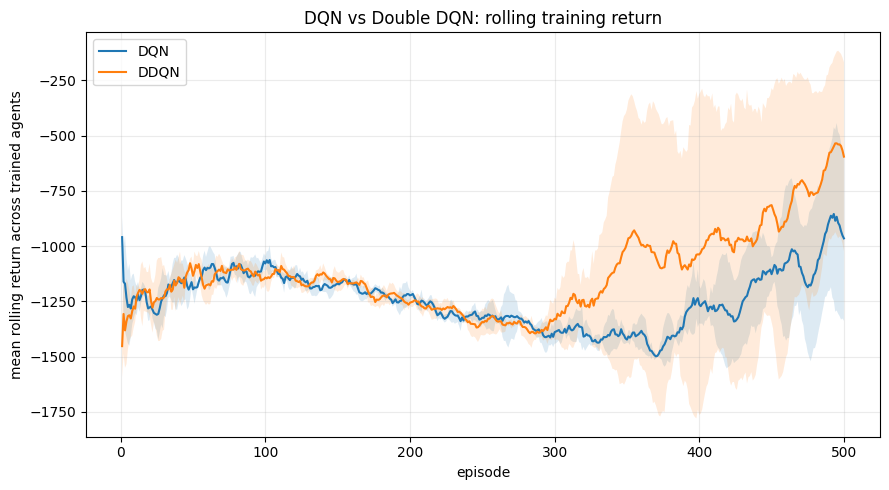

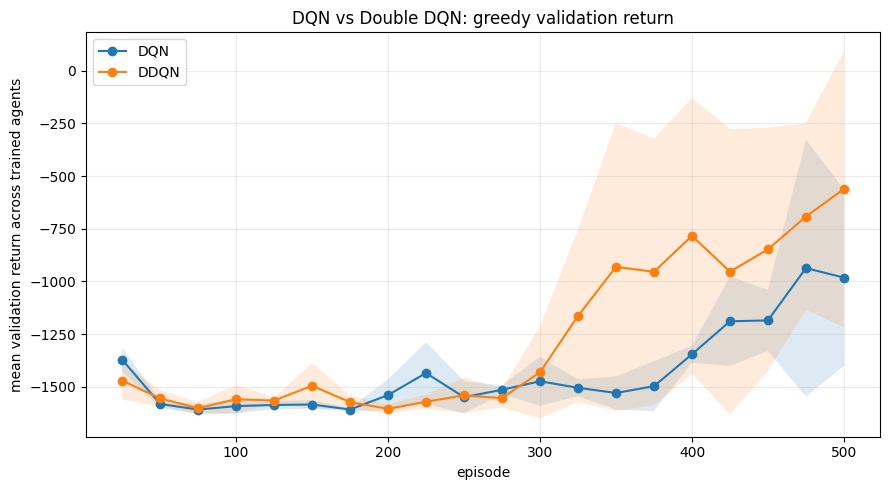

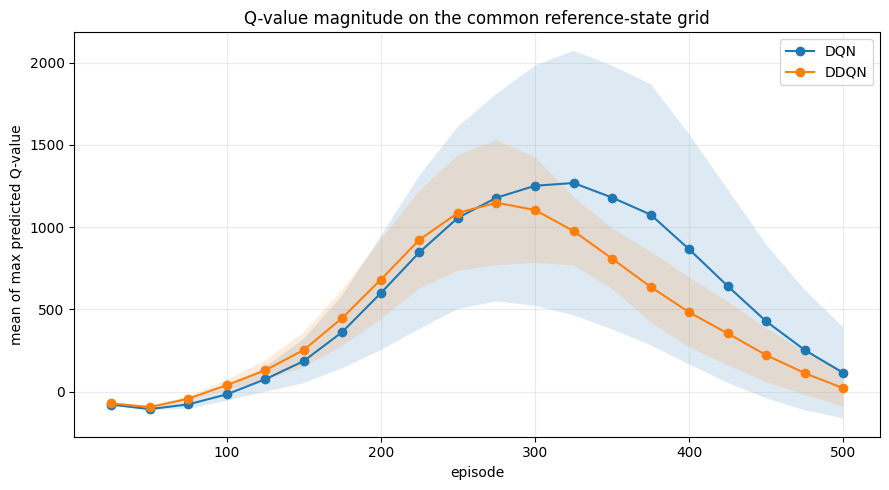

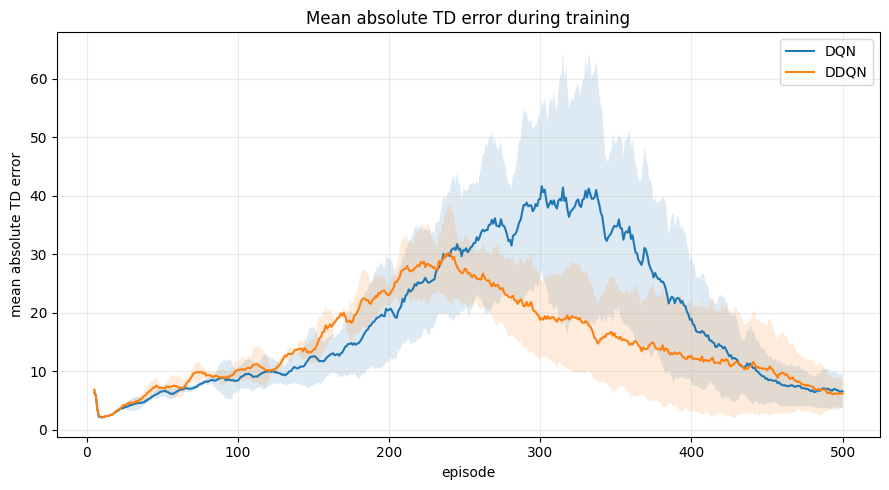

In [13]:
def load_history(algorithm, run_number):
    path = run_dir(algorithm, run_number) / "training_history.csv"
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def aggregate_history_metric(algorithm, record_type, x_col, y_col):
    frames = []
    for r in RUN_NUMBERS:
        h = load_history(algorithm, r)
        s = h[h["record_type"] == record_type][[x_col, y_col]].copy()
        s["run_number"] = r
        frames.append(s)
    combined = pd.concat(frames, ignore_index=True)
    return combined.groupby(x_col)[y_col].agg(["mean", "std", "count"]).reset_index()


def compare_plot(record_type, y_col, title, ylabel, marker=None):
    fig, ax = plt.subplots(figsize=(9, 5))
    for algorithm in ["DQN", "DDQN"]:
        d = aggregate_history_metric(algorithm, record_type, "episode", y_col)
        ax.plot(d["episode"], d["mean"], label=algorithm, marker=marker)
        ax.fill_between(
            d["episode"],
            d["mean"] - d["std"].fillna(0),
            d["mean"] + d["std"].fillna(0),
            alpha=0.15,
        )
    ax.set_title(title)
    ax.set_xlabel("episode")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


if SHOW_ANALYSIS_PLOTS:
    try:
        compare_plot(
            "episode", "rolling_return_10",
            "DQN vs Double DQN: rolling training return",
            "mean rolling return across trained agents"
        )
        compare_plot(
            "validation", "validation_mean_return",
            "DQN vs Double DQN: greedy validation return",
            "mean validation return across trained agents",
            marker="o"
        )
        compare_plot(
            "validation", "mean_max_q",
            "Q-value magnitude on the common reference-state grid",
            "mean of max predicted Q-value",
            marker="o"
        )
        compare_plot(
            "update_summary", "mean_abs_td_error",
            "Mean absolute TD error during training",
            "mean absolute TD error"
        )
    except (FileNotFoundError, KeyError, pd.errors.EmptyDataError) as e:
        print("Plots skipped until all six histories exist:", e)

Agent-level evidence


,algorithm,run_number,best_validation_return,best_validation_std,best_validation_episode,best_validation_step,runtime_minutes,final_mean_max_q,final_mean_abs_q,mean_return,std_return,upright_pct,mean_abs_angle_deg,mean_abs_torque,max_torque_pct,mean_time_to_first_upright_steps,mean_longest_upright_steps,episode_reach_rate_pct,episodes
0,DQN,1,-595.667,106.830,500,100000,10.395,-202.173,205.169,-610.564,57.919,22.667,57.272,1.830,85.400,50.833,14.767,100.000,30
1,DQN,2,-389.888,283.143,475,95000,10.243,371.524,367.538,-428.211,253.207,17.233,47.840,1.320,62.717,93.900,9.233,100.000,30
2,DQN,3,-1325.914,289.623,400,80000,10.519,1462.860,1453.007,-1305.735,220.004,1.550,102.074,1.508,57.783,85.200,1.733,16.667,30
3,DDQN,1,-672.506,767.149,400,80000,9.705,679.206,667.090,-1238.638,521.066,14.400,78.842,1.693,69.283,27.000,28.767,16.667,30
4,DDQN,2,-144.398,133.830,500,100000,9.054,97.458,95.371,-215.583,150.367,78.050,25.395,1.340,40.283,43.767,155.967,100.000,30
5,DDQN,3,-222.585,147.502,500,100000,8.850,-107.076,111.649,-191.470,103.024,79.817,25.859,0.935,46.150,39.267,159.467,100.000,30


Algorithm-level comparison


,algorithm,mean_of_agent_returns,std_across_agent_mean_returns,mean_upright_pct,mean_abs_angle_deg,mean_abs_torque,mean_reach_rate_pct,mean_longest_upright_steps,mean_final_max_q,mean_runtime_minutes
0,DQN,-781.503,463.063,13.817,69.062,1.553,72.222,8.578,544.071,10.386
1,DDQN,-548.564,597.743,57.422,43.365,1.323,72.222,114.733,223.196,9.203


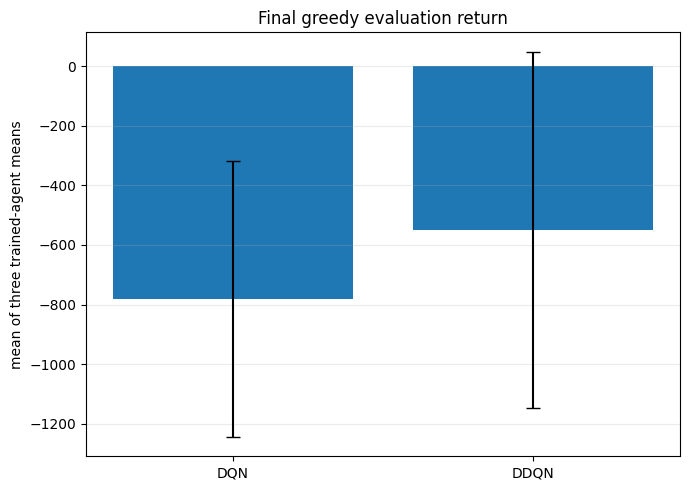

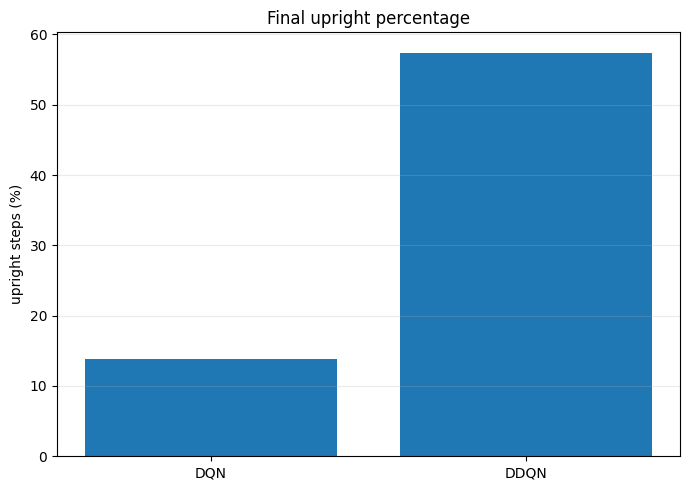

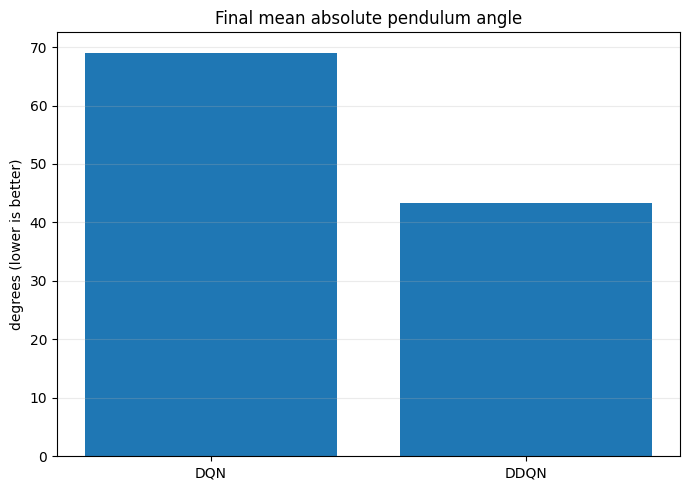

In [14]:
def load_final_summaries():
    if not AGENT_SUMMARY_PATH.exists() or not ALGORITHM_SUMMARY_PATH.exists():
        raise FileNotFoundError("Run final evaluation first.")
    return pd.read_csv(AGENT_SUMMARY_PATH), pd.read_csv(ALGORITHM_SUMMARY_PATH)


if ALGORITHM_SUMMARY_PATH.exists():
    agent_summary, algorithm_summary = load_final_summaries()

    print("Agent-level evidence")
    display(agent_summary.round(3))

    print("Algorithm-level comparison")
    display(
        algorithm_summary[[
            "algorithm",
            "mean_of_agent_returns",
            "std_across_agent_mean_returns",
            "mean_upright_pct",
            "mean_abs_angle_deg",
            "mean_abs_torque",
            "mean_reach_rate_pct",
            "mean_longest_upright_steps",
            "mean_final_max_q",
            "mean_runtime_minutes",
        ]].round(3)
    )

    if SHOW_ANALYSIS_PLOTS:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.bar(
            algorithm_summary["algorithm"],
            algorithm_summary["mean_of_agent_returns"],
            yerr=algorithm_summary["std_across_agent_mean_returns"],
            capsize=5,
        )
        ax.set_title("Final greedy evaluation return")
        ax.set_ylabel("mean of three trained-agent means")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        plt.show()

        fig, ax = plt.subplots(figsize=(7, 5))
        ax.bar(algorithm_summary["algorithm"], algorithm_summary["mean_upright_pct"])
        ax.set_title("Final upright percentage")
        ax.set_ylabel("upright steps (%)")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        plt.show()

        fig, ax = plt.subplots(figsize=(7, 5))
        ax.bar(algorithm_summary["algorithm"], algorithm_summary["mean_abs_angle_deg"])
        ax.set_title("Final mean absolute pendulum angle")
        ax.set_ylabel("degrees (lower is better)")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        plt.show()
else:
    print("Final summary tables/plots will appear after final evaluation.")

# 10. Evidence-based discussion

## 10.1 Control performance: DDQN produced two strong balancing policies

Across the three independently trained agents, the descriptive mean final return was:

- **DQN:** `-781.5`
- **DDQN:** `-548.6`

Because only three trained agents were available per method and variability was high, this difference should be treated as **descriptive evidence**, not a strong population-level statistical claim.

The individual runs reveal the result more clearly. Two of the three DDQN agents learned strong policies:

- `DDQN run 2`: return `-215.6`, upright `78.1%`
- `DDQN run 3`: return `-191.5`, upright `79.8%`

No DQN agent exceeded `22.7%` upright time. However, `DDQN run 1` remained poor (`-1238.6`), so DDQN did not guarantee successful learning.

At the algorithm-summary level, DDQN also showed:

- upright time: `57.4%` vs DQN `13.8%`;
- mean absolute angle: `43.4°` vs `69.1°`;
- longest continuous upright period: `114.7` vs `8.6` steps;
- mean absolute torque: `1.32` vs `1.55`.

These physical metrics show that the descriptive return advantage corresponds to substantially better **sustained balancing**, not just a numerical reward difference.

## 10.2 Reaching upright and staying upright are different

The mean episode reach rate was exactly the same for both methods: **72.2%**.

This is an important result. DDQN's advantage was not that a larger fraction of episodes touched the upright region at least once. Instead, successful DDQN agents were much better at **remaining** balanced after reaching it, as reflected by their much longer upright runs and higher overall upright percentages.

## 10.3 Q-value behaviour: consistent with the DDQN motivation, but not proof

At the selected checkpoints, the mean maximum-Q diagnostic on the common deterministic reference-state grid was:

- **DQN:** `544.1`
- **DDQN:** `223.2`

However, this aggregate difference is strongly influenced by individual runs. In particular:

| Algorithm | Run | Final return | Final max-Q diagnostic |
|---|---:|---:|---:|
| DQN | 1 | -610.6 | -202.2 |
| DQN | 2 | -428.2 | 371.5 |
| DQN | 3 | -1305.7 | **1462.9** |
| DDQN | 1 | -1238.6 | 679.2 |
| DDQN | 2 | -215.6 | 97.5 |
| DDQN | 3 | -191.5 | -107.1 |

DQN Run 3 is especially notable: it produced an extreme positive maximum-Q diagnostic while achieving the worst DQN control return. This co-occurrence is qualitatively **consistent with** the overoptimism concern motivating Double DQN.

It does **not** establish that DQN overestimated by a particular amount. The true \(Q^*\) values for the reference states are unknown, so the diagnostic cannot measure ground-truth estimation bias.

## 10.4 Run-to-run consistency: the original stability expectation was not supported

Final-return SD across the three independently trained agents was:

- **DQN:** `463.1`
- **DDQN:** `597.7`

Therefore DDQN did **not** improve final-policy consistency in this experiment. Its higher SD was caused mainly by the contrast between one failed DDQN run and two strong ones.

This motivates an important distinction:

- **value-estimation behaviour** appeared less extreme on average under DDQN;
- **final-policy reproducibility** across independent training runs did not improve.

Treating both as a single concept called “stability” would hide this result.

## 10.5 Relationship to the research literature

The findings partially align with van Hasselt, Guez and Silver's DDQN motivation. Separating Online-network action selection from Target-network evaluation was associated here with stronger descriptive average control and less extreme aggregate max-Q behaviour, while leaving the network architecture unchanged.

However, this small Pendulum experiment does not reproduce every possible advantage of DDQN. One DDQN run still failed and across-run return variability was higher than Standard DQN. The result is therefore best described as **partial empirical support** rather than universal superiority.

## 10.6 Limitations

1. Only **three independently trained agents** were available per method, so the experiment is too small for strong population-level inference.
2. Only one environment configuration (`g=10`) was studied here.
3. Pendulum's continuous torque had to be discretised to five actions for DQN/DDQN.
4. Random initial states introduce evaluation and validation variability.
5. Hyperparameters were intentionally kept identical rather than retuned for DDQN; this strengthens control of the algorithmic comparison but may not give either method its individually optimal setup.
6. Maximum-Q magnitude is not a direct ground-truth overestimation measurement.


# 11. Final results summary

## Algorithm-level summary

| Metric | DQN | DDQN | Interpretation |
|---|---:|---:|---|
| Mean agent return ↑ | -781.5 | **-548.6** | DDQN better descriptively |
| SD across agent means ↓ | **463.1** | 597.7 | DDQN did not reduce run-to-run variation |
| Upright percentage ↑ | 13.8% | **57.4%** | DDQN substantially higher |
| Mean absolute angle ↓ | 69.1° | **43.4°** | DDQN closer to upright |
| Mean absolute torque ↓ | 1.55 | **1.32** | DDQN used somewhat less control effort |
| Episode reach rate ↑ | **72.2%** | **72.2%** | Equal |
| Mean longest upright run ↑ | 8.6 | **114.7** | DDQN sustained balance much longer |
| Mean final max-Q diagnostic | 544.1 | 223.2 | DDQN lower on average; not direct proof of true bias |
| Mean runtime | 10.4 min | 9.2 min | Similar scale; DDQN not computationally costly here |

## Interpretation rule

The strongest defensible conclusion is **not** “DDQN is always more stable.” It is:

> Across these three runs, DDQN produced two strong balancing policies and better descriptive aggregate control, together with less extreme average maximum-Q behaviour, but one DDQN run failed and across-agent return variability remained high.


# 12. References and source-to-implementation mapping

Only sources directly relevant to the implemented method or its interpretation are included.

| Source | Main idea used here | Connection to this notebook |
|---|---|---|
| **Mnih, V., et al. (2015). _Human-level control through deep reinforcement learning._ Nature, 518, 529–533. DOI: 10.1038/nature14236.** | Deep Q-Network, replay memory and Target network | Forms the Standard-DQN baseline mechanisms used in both methods |
| **van Hasselt, H. (2010). _Double Q-learning._ Advances in Neural Information Processing Systems, 23.** | Maximisation-related positive bias and estimator separation | Motivates separating action selection from evaluation |
| **van Hasselt, H., Guez, A., & Silver, D. (2016). _Deep Reinforcement Learning with Double Q-Learning._ AAAI, 30(1), 2094–2100. DOI: 10.1609/aaai.v30i1.10295.** | Double DQN target: Online selection + Target evaluation | This is the single algorithmic modification tested |
| **Brockman, G., et al. (2016). _OpenAI Gym._ arXiv:1606.01540.** | Standard RL environment interface | Supports the Gym-based experimental setting |
| **OpenAI Gym 0.17.3 Pendulum implementation** | Pendulum observation, reward/dynamics and torque bounds | Supports the exact environment version and preprocessing/action-discretisation choices |

The literature progression remains intentionally focused:

**Q-learning maximisation issue → DQN baseline → Double-Q idea → Double DQN → controlled Pendulum experiment.**

This avoids superficial name-dropping of unrelated DQN extensions that were not implemented.


# 13. Conclusion

This experiment extended the Standard DQN from the gravity study by changing only its bootstrap-target calculation to Double DQN. Architecture, replay memory, optimiser, exploration schedule, target-network update policy, action grid and training budget were held constant.

Across the three independently trained agents, DDQN achieved a better **descriptive** mean greedy return (`-548.6` vs `-781.5`) and much stronger physical balancing behaviour. Two of three DDQN agents maintained the pendulum upright for about `78–80%` of their evaluation steps, whereas no DQN agent exceeded `22.7%`. The equal `72.2%` episode reach rate shows that the main difference was not simply reaching upright; successful DDQN policies were better at **staying** upright.

DDQN also produced a lower aggregate maximum-Q diagnostic (`223.2` vs `544.1`). DQN Run 3 combined an extreme positive max-Q value (`1462.9`) with very poor realised control (`-1305.7`), a pattern qualitatively consistent with the overoptimism problem that motivates Double DQN. Because ground-truth \(Q^*\) values are unavailable, this cannot be interpreted as a measured amount of true overestimation.

The original expectation of improved run-to-run consistency was **not supported**. DDQN's across-agent return SD was higher (`597.7` vs `463.1`) because one DDQN run failed while two were strong. With only three trained agents per method, the findings should therefore be read as careful descriptive evidence rather than a strong population-level claim.

Overall, the experiment provides **partial support** for Double DQN as a targeted improvement over Standard DQN in this discretised Pendulum setting: it produced stronger observed control and less extreme aggregate Q-value behaviour, but it did not eliminate sensitivity to independent training runs.
